# Introduction to Computer Programming and Numerical Methods

> **Mohamad M. Hallal, PhD** <br> Teaching Professor, UC Berkeley

[![License](https://img.shields.io/badge/license-CC%20BY--NC--ND%204.0-blue)](https://creativecommons.org/licenses/by-nc-nd/4.0/)
***

# Taylor Series

1. [**Taylor Series**](#s1)
2. [**Approximating Functions**](#s2)
3. [**Truncation Errors**](#s3)

***

# 0. Motivation

Many functions like $\sin(x)$, $\cos(x)$, $e^x$, and $\log(x)$ play a fundamental role in engineering and science, but how does a computer actually represent and compute these functions? In fact, for many functions routinely encountered by engineers and scientists, explicit computation is virtually unattainable. In practice, these intricate functions are approximated using simpler polynomial expressions, which is the Taylor series of a function. However, since these are approximations, they inherently introduce some level of error. Hence, it is imperative to gain a comprehensive understanding of how these approximations work as well as their limitations.

**Learning objectives:**

* Formulate mathematical functions using Taylor series
* Implement these Taylor series approximations in Python
* Estimate the error resulting from these approximations

# 1. Taylor Series <a id="s1"></a>

A **Taylor series** of a function is an infinite sum of polynomials expressed in terms of the function's derivatives at a single point, $a$. The motive is that polynomials tend to be much easier to compute, differentiate, integrate, and deal with overall. Mathematically, the Taylor series of a function, $f(x)$, that is infinitely differentiable at a real or complex number $a$ is defined as:

$$ f(x) = f(a)+\frac {f'(a)}{1!} (x-a)+ \frac{f''(a)}{2!} (x-a)^2+\frac{f'''(a)}{3!}(x-a)^3+ \cdots = \sum_{n = 0}^{\infty} \frac{f^{(n)}(a)}{n!}(x-a)^n$$

where $f^{(n)}$ is the $n^\mathrm{th}$ derivative of $f$

<br>

Don't let the mathematical notation scare you. In a Taylor series we are getting a function that:
* matches $f(x)$ at $x=a$ exactly using the first term, $f(a)$
* matches $f'(x)$ at $x=a$ exactly using the second term, $f'(a)$
* matches $f''(x)$ at $x=a$ exactly using the third term, $f''(a)$
* $\dots$
* matches $f^{(n)}(x)$ at $x=a$ exactly using the $n^{th}$ term, $f^{(n)}(a)$

For example, let $f(x) = \cos(x)$. We know that $f'(x) = -\sin(x)$, $f''(x) = -\cos(x)$, $f'''(x) = \sin(x)$, $\dots$ If we take the Taylor series expansion around $a=0$:

$$\cos(x) = \frac{\cos(0)}{0!}x^0 + \frac{-\sin(0)}{1!}x^1 + \frac{-\cos(0)}{2!}x^2 + \frac{\sin(0)}{3!}x^3 + \frac{\cos(0)}{4!}x^4 + \frac{-\sin(0)}{5!}x^5 + \cdots = \frac{1}{0!}x^0  + \frac{-1}{2!}x^2  + \frac{1}{4!}x^4 + \cdots$$

The expansion can be written compactly by the formula:

$$\cos(x) = \sum_{n = 0}^{\infty} \frac{(-1)^n}{(2n)!}x^{2n}$$

which ignores the terms that contain $\sin(0)$ (i.e., the odd terms). Take a moment and make sure that the summation notation makes sense to you.

So, we have rewritten the cosine function as a sum of polynomials, which only include addition, subtraction, multiplication, division, and integer exponents, without any complicated functions.

<div class="alert alert-block alert-warning"> <b>NOTE!</b> A Taylor series that is centered around $a=0$ is called a Maclaurin series. This is just a special case of a Taylor series, so we will refer to both simply as Taylor series.</div>

# 2. Approximating Functions <a id="s2"></a>

Taylor series allow representing complicated functions as infinite sums of simple polynomials, which involve basic arithmetic operations such as addition, subtraction, multiplication, division, and integer powers. These operations are easily dealt with on a computer. However, using infinite sums is impractical, as computers cannot do infinitely many computations. So, in practice, we truncate the Taylor series by only taking a finite number of terms. Specifically, functions are approximated by using an **$N^{th}$ order Taylor series approximation**, which essentially truncates the Taylor expansion at a chosen $n = N$. The new polynomial function should be close enough to the actual function so far as we don't stray too far from $x=a$. The idea here is simple in principle:
* Functions can be represented as infinite sums of polynomials
* Computers cannot do infinitely many computations
* Stop the sum at some $n=N$ and ignore the rest of the sum for $n>N$
* Now $f(x)$ is *approximated* by a finite sum of polynomials

For cosine, the truncated expansion can be written compactly by the formula:

$$\cos(x) \approx \sum_{n = 0}^{N} \frac{(-1)^n}{(2n)!}x^{2n}$$

<div class="alert alert-block alert-info"> <b>TRY IT!</b> Write a function <code>myCos(X, N)</code> which computes cosine at every radian value in <code>X</code>, which may be a scalar or a <code>np.ndarray</code> using the $N^{th}$ term from the equation above. The input <code>N</code> is a non-negative scalar integer. The output should be of the same type and size as <code>X</code>.</div>

In [1]:
import math

# Define function
def myCos(X, N):
    # initiate value
    cos_approx = 0
    
    # iterate
    for n in range(N+1):
        # update the values in each iteration
        cos_approx = cos_approx + (-1)**n / math.factorial(2*n) * X ** (2*n)
        
    return cos_approx

<div class="alert alert-block alert-info"> <b>TRY IT!</b> Try out your function using the following examples <code>myCos(np.pi/6, 0)</code>, <code>myCos(np.pi/6, 1)</code>, <code>myCos(np.pi/6, 15)</code>.</div>

In [2]:
import numpy as np

print(f'cos(30) ~ {myCos(np.pi/6, 0)} (using N=0)') # approximation of cos(30) using N = 0

print(f'cos(30) ~ {myCos(np.pi/6, 1)} (using N=1)') # approximation of cos(30) using N = 1

print(f'cos(30) ~ {myCos(np.pi/6, 15)} (using N=15)') # approximation of cos(30) using N = 15

print(f'cos(30) = {np.cos(np.pi/6)} (using np.cos())') # approximation of cos(30) using np.cos()

cos(30) ~ 1.0 (using N=0)
cos(30) ~ 0.8629221610959812 (using N=1)
cos(30) ~ 0.8660254037844386 (using N=15)
cos(30) = 0.8660254037844387 (using np.cos())


<div class="alert alert-block alert-info"> <b>TRY IT!</b> Plot the values of $cos(X)$ using <code>np.cos()</code> for <code>X = np.linspace(-np.pi, np.pi, 100)</code>. Then use your function <code>myCos(X, N)</code> to plot the values for <code>N  = [1, 2, 3, 4]</code>.</div>

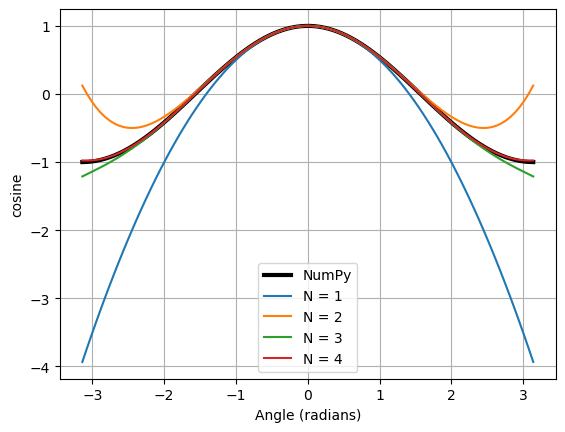

In [3]:
import matplotlib.pyplot as plt

# create figure and axes
fig = plt.figure()
ax = plt.axes()

# Define X and N
X = np.linspace(-np.pi, np.pi, 100)
N  = [1, 2, 3, 4]

# Plot np.cos(X)
ax.plot(X, np.cos(X) , 'k', lw = 3, label = 'NumPy')

# Plot Taylor expansion for different N
for value in N:
    ax.plot(X, myCos(X, value), label = f'N = {value}')

# control multiple properties
ax.set(xlabel = 'Angle (radians)', ylabel='cosine')    

# add legend
ax.legend()  

# add grid line
ax.grid()

# display the figure 
plt.show()

As you can see, when enough terms are used, the approximation approaches the results from `np.cos()` quickly, even for angles not close to $a = 0$.

# 3. Truncation Errors <a id="s3"></a>

As discussed in previous sections, a computer can only store a finite number of bits. As such, most computational tasks inherently involve approximations. Specifically with Taylor series, accurately representing a function requires an infinite sum of terms, which is impractical. By truncating the series after a finite number of terms, we introduce truncation errors.

In numerical analyses, two primary sources of error emerge:
1. Round-off errors: difference between an approximation of a number used in computation and its exact (correct) value.
2. Truncation errors: difference between an actual and a truncated, or cut-off, value.

We have already discussed round-off errors, which are due to the inexactness in the representation of real numbers in a computer. So, we will focus on truncation errors. Truncation errors occur due to the approximation of an infinite sum by a finite sum, such as when employing the $N^{th}$ order Taylor series to approximate a function.

If we can evaluate the function exactly, computing the error would be straightforward. However, the motivation of Taylor series lies in approximating functions that cannot be evaluated exactly. Thus, since the actual value cannot be exactly calculated for many functions, we focus on calculating an *approximate error*. Let's consider the Taylor series expansion of $f(x) = \cos(x)$ around $a=0$:

$$f(x) = \cos(x) = 1  - \frac{x^2}{2!}  + \frac{x^4}{4!} - \frac{x^6}{6!}  + \frac{x^8}{8!} - \cdots$$

If we use a second-order (quadratic) approximation of $f(x) = \cos(x)$, we obtain:

$$f(x) = \cos(x) = \underbrace{1  - \frac{x^2}{2!}}_{2^{nd} \text{ order approximation}}  + \underbrace{\frac{x^4}{4!} - \frac{x^6}{6!}  + \frac{x^8}{8!} - \cdots}_{\text{remainder}}$$

Therefore, we would approximate $f(x)$ as $f(x)\approx 1  - \dfrac{x^2}{2!}$

For values of $x$ close to $a=0$, the largest term in the remainder is the $x^4$ term (since for small values of $x$ like 0.01, $x^6$ will be even smaller, $x^8$ even smaller than that, etc). This means that if we use a second-order approximation for $\cos(x)$, then we expect our error to be about the same size as $x^4$. In this case, it is common to rewrite the truncated Taylor series as:

$$f(x) \approx 1  - \frac{x^2}{2!} + \mathcal{O}\left(x^4\right)$$

where $\mathcal{O}\left(x^4\right)$ reads "Big-O of $x^4$" indicates that the expected error for approximations close to $a=0$ is about the same size as $x^4$.

Notice that we don't explicitly say that the error is $x^4$. Instead we are just saying that using the quadratic function $f(x)\approx 1  - \dfrac{x^2}{2!}$ to approximate $\cos(x)$ for values of $x$ near $a=0$ will result in errors that are proportional to $x^4$.

To get a more accurate approximation of the truncation error, we will use the entire next term, including any coefficients. So, when using the quadratic function $f(x)\approx 1  - \dfrac{x^2}{2!}$, the approximate error is $\dfrac{x^4}{4!}$. More generally, the truncated $N^{th}$ expansion plus the estimated error for cosine can be written as:

$$f(x) \approx \underbrace{\sum_{n = 0}^{N} \frac{(-1)^n x^{2n}}{(2n)!}}_{\text{Approximation}} + \underbrace{\frac{x^{2(N+1)}}{(2(N+1))!}}_{\text{Error}}$$

So, in general, the error of a truncated Taylor series is approximately the next term in the expansion after the cut-off, which tends to be the largest remaining contribution to the approximation. This approximation is only good for values of $x$ that are close to the center of the Taylor series $a$.

The table below shows approximations of $\cos(0.3)$ with different order polynomials. Using `math.cos(0.3)`, we have Python's approximation $\cos(0.3)\approx 0.9553364891$. If we use this as a reference, we can compare the estimated error from the next term in the Taylor series with the absolute error between the Taylor series approximation and the reference value.

| Taylor Series         | Approximation | Estimated Error                                       | Absolute Error |
| :-------------------- | :------------ | :---------------------------------------------------- | :------------- |
| $0^{th} \text{ order}$ | $1.0$         | $\dfrac{x^2}{2!}=\dfrac{0.3^2}{2}$ $=0.045$          | $0.0446635109$ |
| $2^{nd} \text{ order}$ | $0.955$       | $\dfrac{x^4}{4!}=\dfrac{0.3^4}{24}$ $=0.0003375$     | $0.0003364891$ |
| $4^{th} \text{ order}$ | $0.9553375$   | $\dfrac{x^6}{6!}=\dfrac{0.3^6}{720}$ $=0.0000010125$ | $0.0000010109$ |

Note that the absolute error is always slightly less than the expected error. Thus, using the next term in the remainder to estimate the truncation error is reasonable.

<div class="alert alert-block alert-info"> <b>TRY IT!</b> Write a function <code>myCos_err(X, N)</code> which returns the absolute value of the estimated error of <code>myCos(X, N)</code> using the <code>N+1</code> term. </div>

In [4]:
def myCos_err(X, N):
    return X**(2*(N+1)) / math.factorial(2*(N+1))

<div class="alert alert-block alert-info"> <b>TRY IT!</b> Use your function <code>myCos_err(X, N)</code> to plot the estimated error for <code>N  = [1, 2, 3, 4]</code> at <code>X = np.linspace(-np.pi, np.pi, 100)</code>.</div>

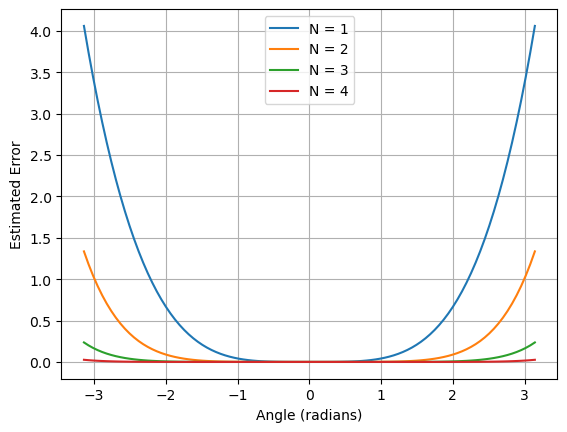

In [5]:
# create figure and axes
fig = plt.figure()
ax = plt.axes()

# Define X and N
X = np.linspace(-np.pi, np.pi, 100)
N  = [1, 2, 3, 4]

# Plot estimated error for different N
for value in N:
    ax.plot(X, myCos_err(X, value), label = f'N = {value}')

# control multiple properties
ax.set(xlabel = 'Angle (radians)', ylabel='Estimated Error')    

# add legend
ax.legend()  

# add grid line
ax.grid()

# display the figure 
plt.show()